# 03 · Chronological modeling and honest evaluation

Ten bounded candidates per horizon. Select on January/July 2021, then freeze and evaluate January/May 2022. This notebook reads the completed models instead of silently retraining.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RUN = Path(__import__("os").environ.get("AMAZON_CLV_RUN", str(ROOT / "runs" / "main")))
assert (RUN / "manifest.json").exists(), "Run python -m amazon_clv run first"
audit = json.loads((RUN / "data_audit.json").read_text())
manifest = json.loads((RUN / "manifest.json").read_text())
pd.set_option("display.max_columns", 20)
print("Source MD5:", audit["md5"], "| Model version:", manifest["run_version"])


Source MD5: 3549d72735b1211ab009ff0177b94bd9 | Model version: amazon-clv-1.0-6efb098a6e


In [2]:
validation = pd.read_csv(RUN / "validation_metrics.csv")
summary = validation.groupby(["horizon","name"]).agg(mean_rmse=("rmse","mean"),mean_capture_20=("capture_20","mean"))
display(summary)
selection = json.loads((RUN / "frozen_selection.json").read_text())
display(selection)
metrics = pd.read_csv(RUN / "test_metrics.csv")
display(metrics.loc[metrics.selected,["horizon","scoring_date","model","mae","rmse","wape","normalized_rmse","predicted_total","actual_total","capture_10","capture_20","adjustment_rate"]])

mean_rmse  mean_capture_20
horizon name                                      
90      hgb_0.05_15    522.197232         0.518871
        hgb_0.05_31    522.778651         0.518256
        hgb_0.1_15     526.856949         0.518745
        hgb_0.1_31     531.263304         0.518210
        ridge_0.1      532.340346         0.519333
        ridge_1        532.338717         0.519333
        ridge_10       532.323276         0.519333
        ridge_100      532.210924         0.519122
        trailing_365   531.390450         0.508360
        trailing_90    644.894687         0.499160
180     hgb_0.05_15    952.029318         0.513986
        hgb_0.05_31    960.146057         0.514908
        hgb_0.1_15     965.563592         0.515519
        hgb_0.1_31     974.375320         0.514106
        ridge_0.1      940.946525         0.516779
        ridge_1        940.944778         0.516779
        ridge_10       940.928510         0.516781
        ridge_100      940.823077         0.516839
        trailing_365   949.278852         0.509591
        trailing_90   1162.438881         0.492419

{'selected': {'90': {'name': 'hgb_0.05_15',
   'kind': 'hgb',
   'learning_rate': 0.05,
   'max_leaf_nodes': 15,
   'complexity': 3},
  '180': {'name': 'ridge_100',
   'kind': 'ridge',
   'alpha': 100,
   'complexity': 2}},
 'selection_rule': '90 first; 180 evaluated after max(raw180, selected90). Equal fold weighting. 1% RMSE band then capture, then simplicity. ML must improve best baseline RMSE.',
 'frozen_before_test': True}

,horizon,scoring_date,model,mae,rmse,wape,normalized_rmse,predicted_total,actual_total,capture_10,capture_20,adjustment_rate
6,90,2022-01-01,hgb_0.05_15,290.276406,528.420429,0.588702,1.071677,2.868293e+06,2460953.61,0.352133,0.533630,0.000000
16,90,2022-05-01,hgb_0.05_15,291.490393,553.410938,0.513564,0.975031,2.739584e+06,2840185.41,0.350638,0.535549,0.000000
25,180,2022-01-01,ridge_100,557.285937,886.969947,0.550147,0.875608,6.336727e+06,5055762.42,0.347192,0.531909,0.013424
35,180,2022-05-01,ridge_100,503.506280,869.903064,0.463137,0.800158,5.904428e+06,5440171.86,0.345835,0.529147,0.043765


## Same serialized model, same predictions
Both historical dates use the same fitted bundle. Coherent 180-day forecasts are max(raw180,90-day forecast). This adjustment was already included in validation.

In [3]:
import joblib
from amazon_clv.pipeline import predict_export
bundle = joblib.load(RUN / "bundle" / "models.joblib")
snapshots = pd.read_parquet(RUN / "snapshots.parquet")
test = snapshots.loc[snapshots.scoring_date.isin(pd.to_datetime(["2022-01-01","2022-05-01"]))]
from threadpoolctl import threadpool_limits
with threadpool_limits(limits=4):
    reloaded = predict_export(bundle,test)
saved = pd.read_parquet(RUN / "customer_predictions.parquet")
np.testing.assert_allclose(reloaded.predicted_spending,saved.predicted_spending,rtol=0,atol=1e-8)
pivot = saved.pivot(index=["customer_id","scoring_date"],columns="horizon",values="predicted_spending")
assert pivot[180].ge(pivot[90]).all()
print("PASS: saved bundle reproduces every test prediction and horizon coherence")

PASS: saved bundle reproduces every test prediction and horizon coherence


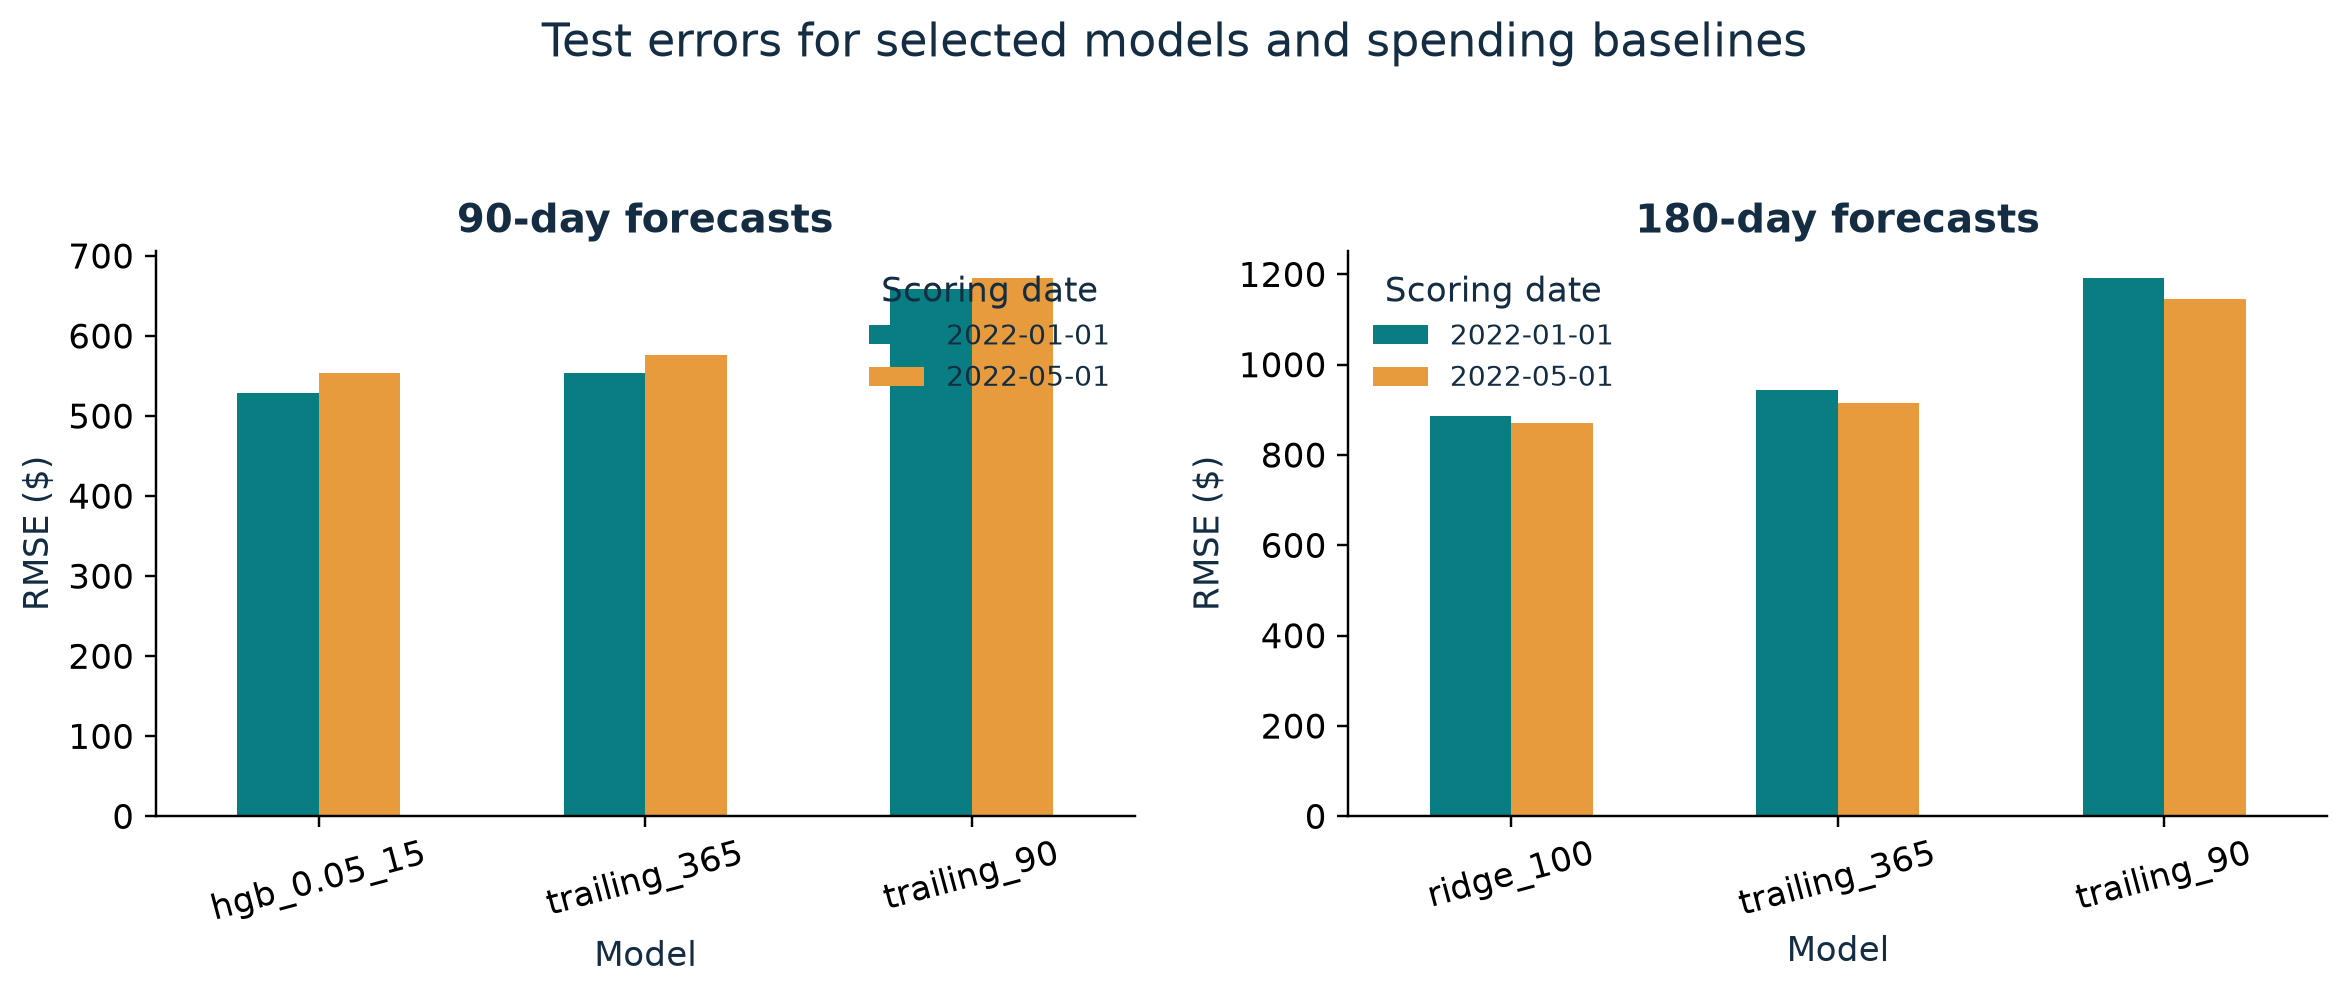

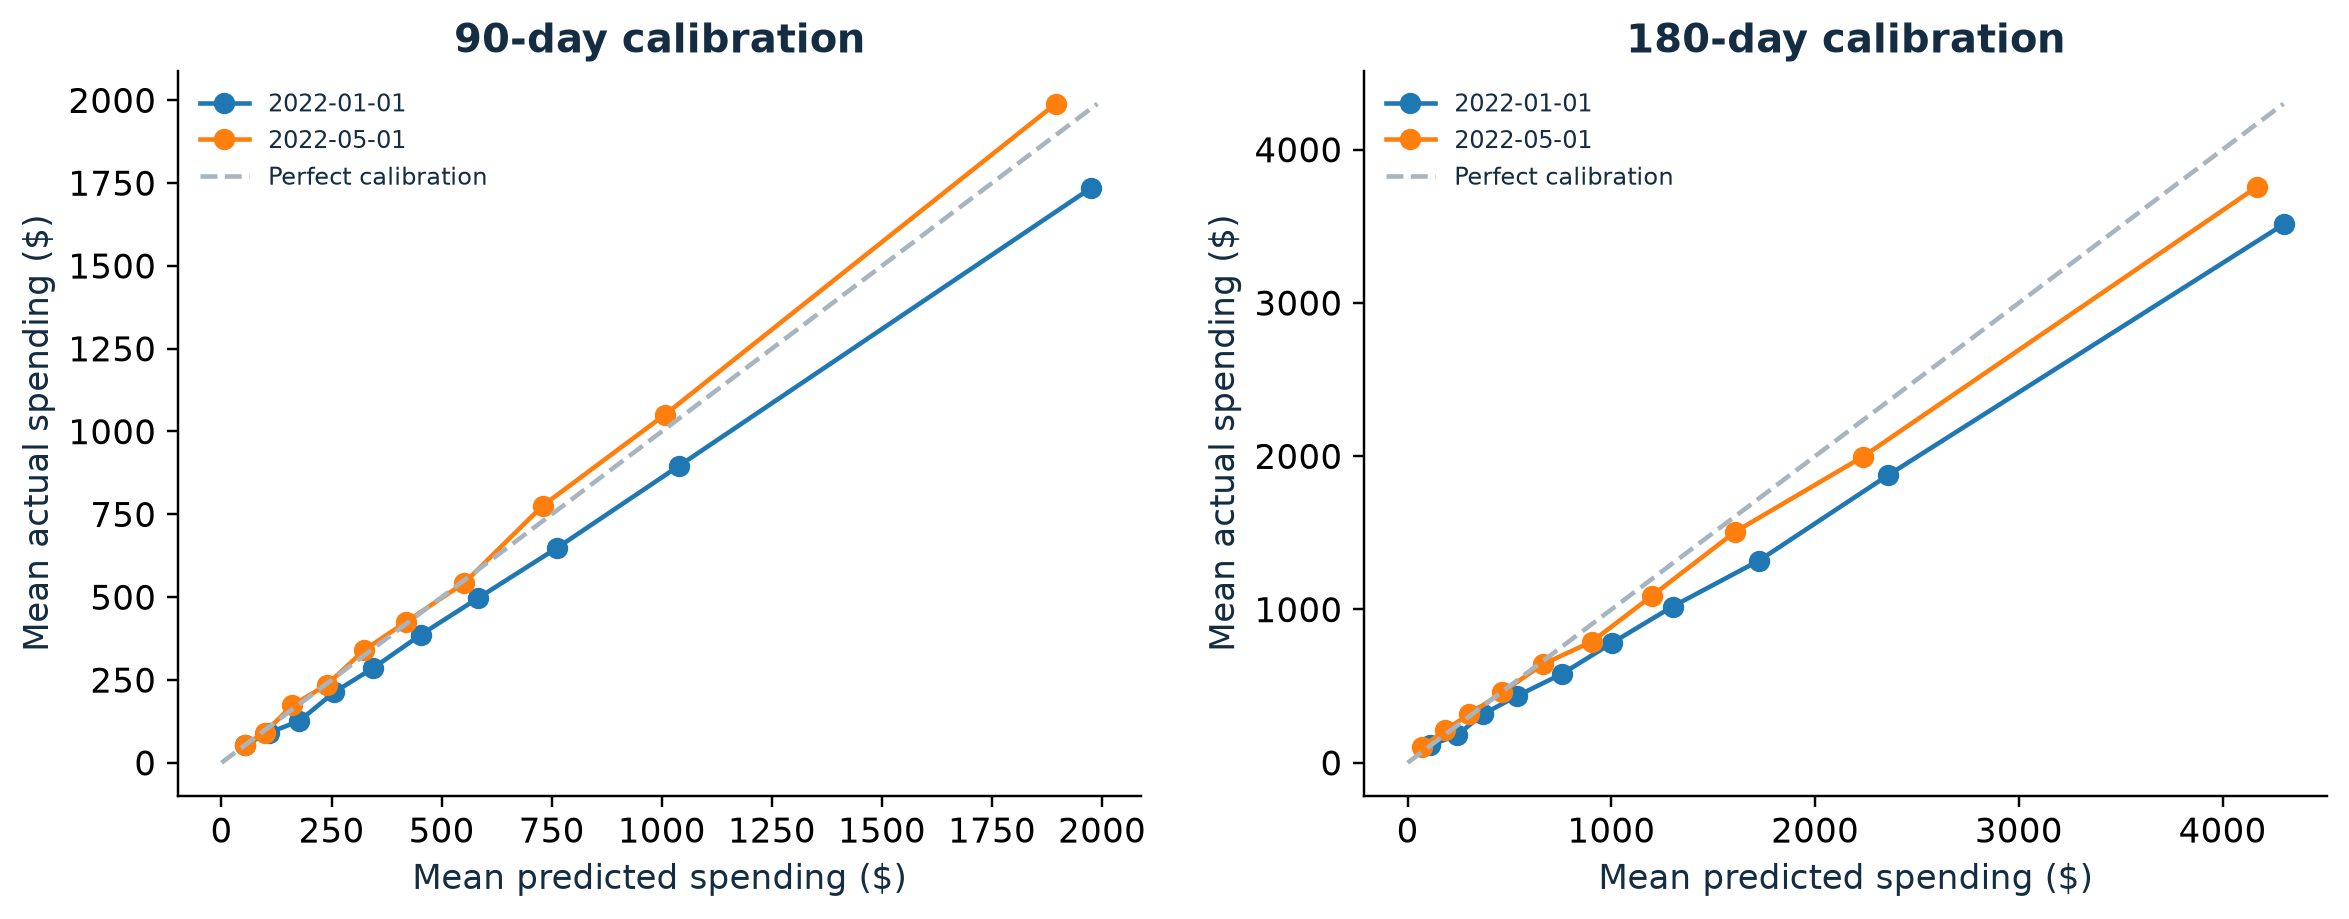

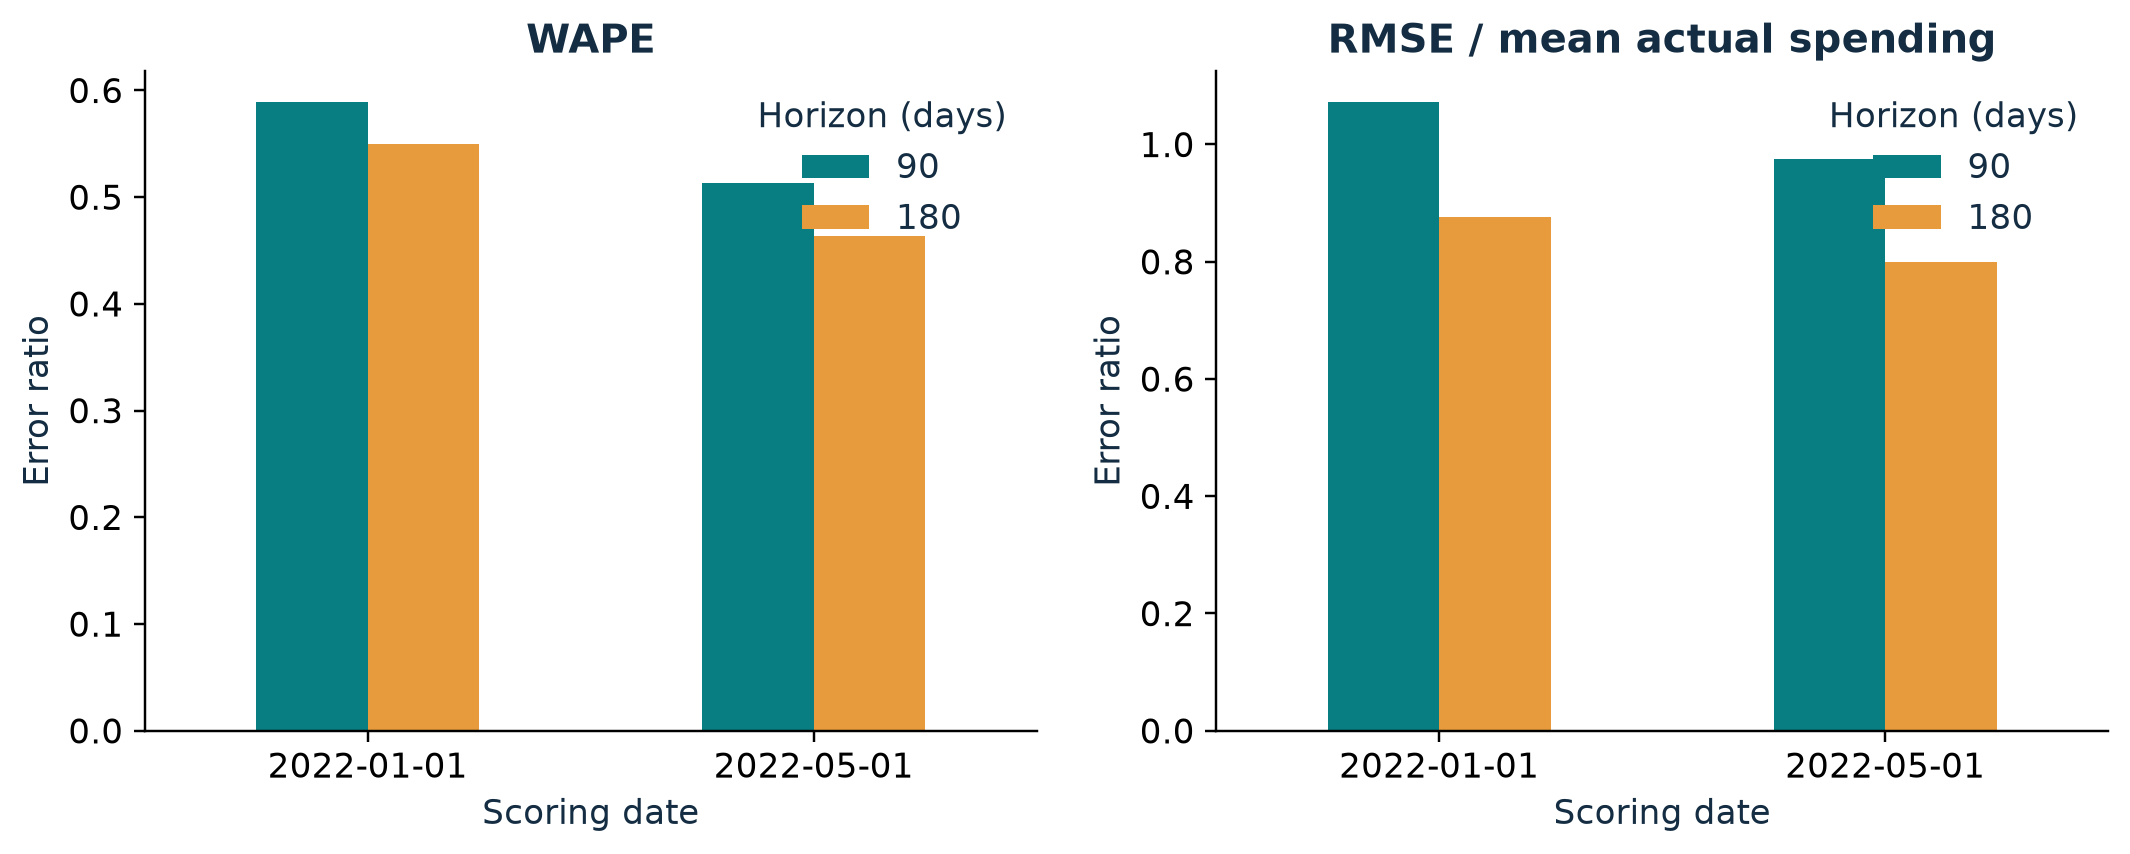

In [4]:
display(Image(filename=str(RUN / "charts" / "model_errors.png")))
display(Image(filename=str(RUN / "charts" / "calibration.png")))
display(Image(filename=str(RUN / "charts" / "horizon_comparison.png")))

## Uncertainty and robustness
500 account-level bootstrap resamples keep repeated account observations together. Intervals are conditional on the fitted models, with temporal/sample-selection uncertainty unresolved. Overlapping test windows are dependent. Smaller 90-day dollar error alone cannot establish a better business horizon.

,horizon,scope,metric,estimate,lower_95,upper_95,resamples,customers
0,90,Both test dates,mae,290.884189,280.442600,300.682894,500,5004
1,90,Both test dates,rmse,541.076233,499.990264,586.250186,500,5004
2,90,Both test dates,wape,0.548446,0.534609,0.562100,500,5004
3,90,Both test dates,normalized_rmse,1.020169,0.961887,1.089321,500,5004
4,90,Both test dates,total_ratio,1.057863,1.036073,1.078076,500,5004
5,90,Both test dates,capture_10,0.350285,0.337162,0.364750,500,5004
6,90,Both test dates,capture_20,0.533287,0.520576,0.546314,500,5004
7,90,Both test dates,capture_20_gain_pp,0.555249,0.029739,1.027467,500,5004
24,180,Both test dates,mae,530.361134,514.115713,546.809535,500,5004
25,180,Both test dates,rmse,878.466854,825.793781,928.102811,500,5004


,horizon,scoring_date,segment,n,mae,rmse,wape,normalized_rmse,predicted_total,actual_total,total_ratio,capture_10,capture_20
0,90,2022-01-01,All customers,4991,290.276406,528.420429,0.588702,1.071677,2.868293e+06,2460953.61,1.165521,0.352133,0.533630
1,90,2022-01-01,Low history (<90 days),35,145.945100,211.422945,1.038014,1.503716,4.791460e+03,4921.01,0.973674,0.220040,0.261178
2,90,2022-01-01,Inactive (>=180 days),317,71.456953,112.023054,1.838757,2.882620,1.906968e+04,12319.11,1.547976,0.171598,0.261500
3,90,2022-01-01,High historical spending (top 10%),500,801.619561,1207.350582,0.466356,0.702397,9.598785e+05,859449.91,1.116852,0.199915,0.327898
4,90,2022-05-01,All customers,5004,291.490393,553.410938,0.513564,0.975031,2.739584e+06,2840185.41,0.964579,0.350638,0.535549
5,90,2022-05-01,Low history (<90 days),6,162.048303,214.323276,1.306262,1.727647,8.987429e+02,744.33,1.207452,0.000000,0.891285
6,90,2022-05-01,Inactive (>=180 days),311,83.037009,248.154177,1.807305,5.401089,1.905868e+04,14288.96,1.333804,0.130232,0.216202
7,90,2022-05-01,High historical spending (top 10%),501,743.018656,1203.078256,0.383574,0.621073,9.200609e+05,970484.78,0.948043,0.203606,0.337837
8,180,2022-01-01,All customers,4991,557.285937,886.969947,0.550147,0.875608,6.336727e+06,5055762.42,1.253367,0.347192,0.531909
9,180,2022-01-01,Low history (<90 days),35,274.708234,405.324466,1.078118,1.590734,1.175225e+04,8918.12,1.317794,0.150754,0.200835


,analysis,scoring_date,horizon,model,rmse,normalized_rmse,capture_20
0,Primary (gift cards retained),2022-01-01,90,hgb_0.05_15,528.420429,1.071677,0.533630
1,Primary (gift cards retained),2022-05-01,90,hgb_0.05_15,553.410938,0.975031,0.535549
2,Primary (gift cards retained),2022-01-01,180,ridge_100,886.969947,0.875608,0.531909
3,Primary (gift cards retained),2022-05-01,180,ridge_100,869.903064,0.800158,0.529147
4,Sensitivity (gift cards excluded),2022-01-01,90,hgb_0.05_31,524.973226,1.096230,0.541909
5,Sensitivity (gift cards excluded),2022-05-01,90,hgb_0.05_31,549.607082,0.995652,0.543343
6,Sensitivity (gift cards excluded),2022-01-01,180,ridge_10,868.235949,0.881820,0.537062
7,Sensitivity (gift cards excluded),2022-05-01,180,ridge_10,857.358295,0.809336,0.533494


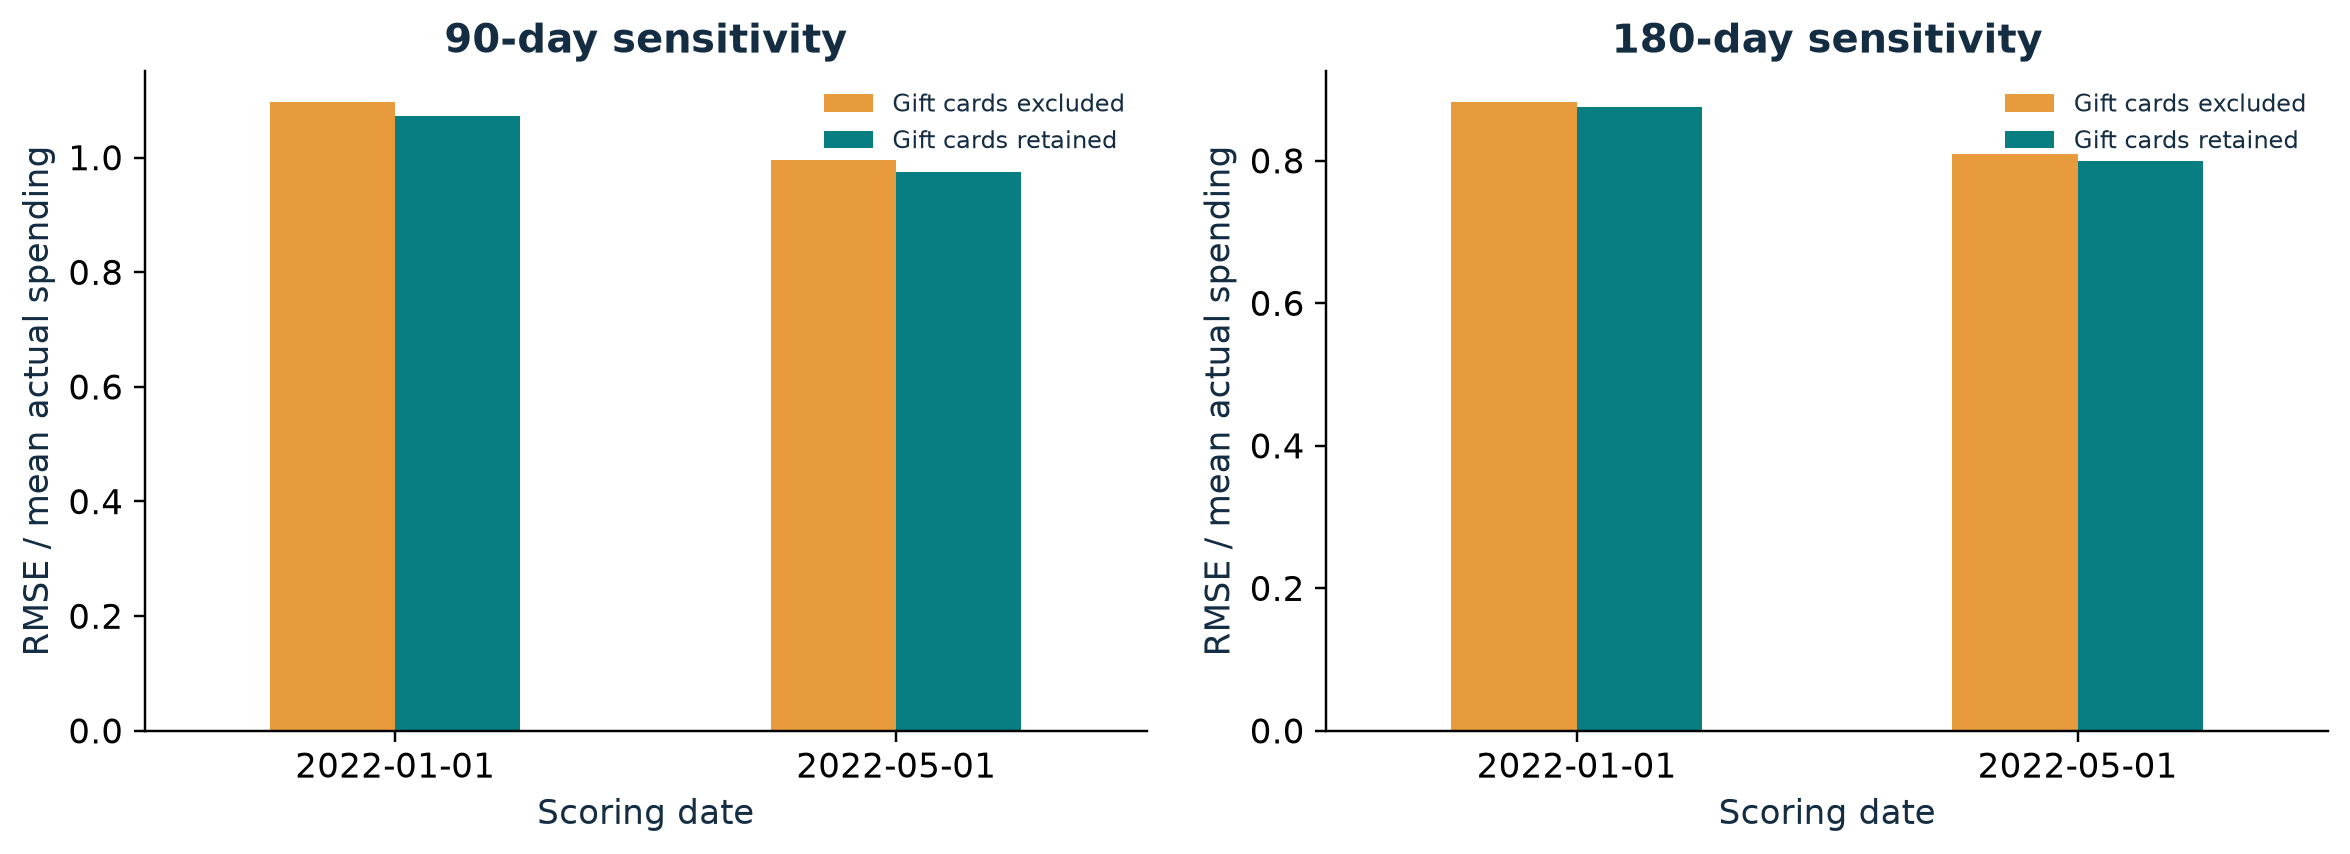

,horizon,feature,rmse_increase,std
53,180,lifetime_spend,112.543719,10.345872
78,180,quantity_365,95.593639,1.731267
25,90,spend_365,82.231547,9.683528
54,180,lifetime_purchase_days,43.281860,0.888194
73,180,categories_180,24.073654,1.267828
77,180,purchase_days_365,19.797308,0.182686
97,180,spend_trend_30,13.048711,0.303266
38,90,category_share_06,7.543841,1.832932
2,90,lifetime_spend,6.770246,2.209038
55,180,spend_30,6.659811,3.556012


In [5]:
ci = pd.read_csv(RUN / "bootstrap_intervals.csv")
display(ci.loc[ci.scope.eq("Both test dates")])
display(pd.read_csv(RUN / "segment_errors.csv"))
display(pd.read_csv(RUN / "gift_sensitivity.csv")[["analysis","scoring_date","horizon","model","rmse","normalized_rmse","capture_20"]])
display(Image(filename=str(RUN / "charts" / "gift_sensitivity.png")))
display(pd.read_csv(RUN / "predictive_associations.csv").sort_values("rmse_increase",ascending=False).head(15))

## Interpretation
Feature importance measures predictive association, not interventions. The gift sensitivity changes the target and can change cohort membership and selected model. Report measured outcomes even if a baseline or alternative horizon is stronger on a particular metric. No test-outcome tuning follows this notebook.